## Examen 2 | Modelo de Varianza: ARCH — GMEXICOB
Aplicamos el modelo Autorregresivo de Heterocedasticidad Condicional (ARCH) al precio de Grupo México
(GMEXICOB), usando los últimos 2 años de datos y probando 4 rezagos
distintos (1, 2, 5, 10 días) para encontrar cuál pronostica mejor.

### El modelo

El modelo ARCH(q) asume que la varianza condicional de hoy depende de los
rendimientos al cuadrado de los últimos $q$ días:

$$\sigma^2_t = \omega + \sum_{i=1}^{q} \alpha_i R^2_{t-i}$$

- $t$: día para el que estimamos la varianza.
- $q$: número de rezagos (cuántos días hacia atrás miramos).
- $\omega$: constante del modelo ($\omega > 0$).
- $\alpha_i$: coeficientes que miden el impacto de los rezagos ($\alpha_i \ge 0$).

La volatilidad es la raíz de la varianza: $\sigma_t = \sqrt{\sigma^2_t}$



In [1]:
import sys, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model 

SRC_PATH = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
sys.path.append(SRC_PATH)

from calculo_rendimientos import calculate_returns

GMEXICO_PATH = os.path.join("..", "datos_historicos", "gmexico_prices.csv")

### Datos: últimos 2 años de GMEXICOB

Reutilizamos `calculate_returns()` y filtramos solo a los últimos 2
años, manteniendo la comparabilidad de la base de datos con los modelos
de media móvil y EWMA del equipo.


In [2]:
# carga y filtros 
df_gmexico = calculate_returns(GMEXICO_PATH)

fecha_fin = df_gmexico.index.max()
fecha_inicio = fecha_fin - pd.DateOffset(years=2)
df_2y = df_gmexico.loc[fecha_inicio:].copy()

print(f"Periodo: {df_2y.index.min().date()} a {df_2y.index.max().date()}")
print(f"Total de dias habiles: {len(df_2y)}")
df_2y.tail()

Periodo: 2024-09-17 a 2026-09-14
Total de dias habiles: 499


,adj_close,simple_return,log_return,cumulative_return
Date,,,,
2026-09-08,229.559998,0.025875,0.025546,116.658060
2026-09-09,228.500000,-0.004618,-0.004628,116.119389
2026-09-10,218.339996,-0.044464,-0.045483,110.956267
2026-09-11,218.300003,-0.000183,-0.000183,110.935943
2026-09-14,213.910004,-0.020110,-0.020315,108.705029


### $R^2$: nuestro proxy de la varianza "real" de cada día

Al igual que con la media móvil, usamos el retorno logarítmico al cuadrado
($R^2$) como aproximación de la varianza observada para evaluar nuestro
pronóstico condicional ARCH.

In [3]:
r = df_2y['log_return']
r2 = r**2
r2.tail()

Date
2026-09-08    6.525810e-04
2026-09-09    2.142035e-05
2026-09-10    2.068680e-03
2026-09-11    3.355731e-08
2026-09-14    4.126949e-04
Name: log_return, dtype: float64

### Estimación de la Varianza Condicional ARCH por rezago

Ajustamos el modelo ARCH para $q \in \{1, 2, 5, 10\}$.

*Nota metodológica:* Para optimizar correctamente los parámetros de máxima verosimilitud en `arch_model`, multiplicamos los retornos por 100 (cambio de escala a porcentaje). Al extraer la varianza, dividimos entre $100^2 = 10,000$ para regresar a la escala original.

In [4]:
rezagos = [1, 2, 5, 10]
sigma2_arch = pd.DataFrame(index=r.index)

# Escalamiento para la convergencia del optimizador
r_pct = r * 100

for q in rezagos:
    # Definimos y ajustamos el modelo ARCH(q)
    am = arch_model(r_pct, vol='ARCH', p=q, mean='Zero', dist='Normal')
    res = am.fit(disp='off')
    
    # Obtenemos la varianza condicional in-sample y regresamos a la escala original
    sigma2_arch[f'var_q{q}'] = res.conditional_volatility**2 / 10000

sigma2_arch.tail()

,var_q1,var_q2,var_q5,var_q10
Date,,,,
2026-09-08,0.000456,0.000456,0.000493,0.000488
2026-09-09,0.000518,0.000518,0.000711,0.000697
2026-09-10,0.000455,0.000456,0.000333,0.000332
2026-09-11,0.000660,0.000659,0.000499,0.000492
2026-09-14,0.000453,0.000455,0.000435,0.000436


### RMSE: ¿cuál modelo ARCH ajusta mejor?

$$RMSE_q = \sqrt{\frac{1}{H}\sum_{t=1}^{H}\left(R_t^2 - \sigma_{t,q}^2\right)^2}$$

Comparamos cada estimación de varianza condicional $\sigma^2_{t,q}$ contra el $R^2_t$ real.
**El modelo con menor RMSE nos indicará el número óptimo de rezagos $q^*$.**

In [5]:
sigma2_rmse = sigma2_arch.dropna()
r2_rmse = r2.loc[sigma2_rmse.index]

rmse = pd.Series(dtype=float)
for q in rezagos:
    rmse[f'var_q{q}'] = np.sqrt((1/len(r2_rmse)) * ((r2_rmse - sigma2_rmse[f'var_q{q}'])**2).sum())

rmse

var_q1     0.001405
var_q2     0.001405
var_q5     0.001412
var_q10    0.001412
dtype: float64

In [6]:
q_opt = int(rmse.idxmin().replace('var_q', ''))
print(f"Rezago óptimo ARCH (menor RMSE): q* = {q_opt} días")
rmse

Rezago óptimo ARCH (menor RMSE): q* = 2 días


var_q1     0.001405
var_q2     0.001405
var_q5     0.001412
var_q10    0.001412
dtype: float64

### Pronóstico de volatilidad para mañana

Usando el modelo ARCH($q^*$) ganador, generamos el pronóstico analítico de la varianza
para mañana ($T+1$) utilizando la función `.forecast()` de la librería.

Para anualizar: $\sigma_{\text{anual}} = \sqrt{252\,\sigma^2_{T+1}}$

In [7]:
# Reajustamos el modelo con el q óptimo para extraer el pronóstico fácilmente
am_opt = arch_model(r_pct, vol='ARCH', p=q_opt, mean='Zero', dist='Normal')
res_opt = am_opt.fit(disp='off')

# Pronóstico de varianza a 1 paso (mañana)
forecast = res_opt.forecast(horizon=1)

# Extraemos el último valor pronosticado y devolvemos a escala original
var_mañana = forecast.variance.iloc[-1, 0] / 10000
vol_anual_manana = np.sqrt(252 * var_mañana)

print(f"Varianza pronosticada para mañana (ARCH q*={q_opt}): {var_mañana:.6f}")
print(f"Volatilidad anualizada pronosticada: {vol_anual_manana:.2%}")

Varianza pronosticada para mañana (ARCH q*=2): 0.000494
Volatilidad anualizada pronosticada: 35.28%


### Gráfica: volatilidad condicional anualizada por modelo ARCH

Visualizamos cómo ajusta cada modelo ARCH la volatilidad condicional en el tiempo.

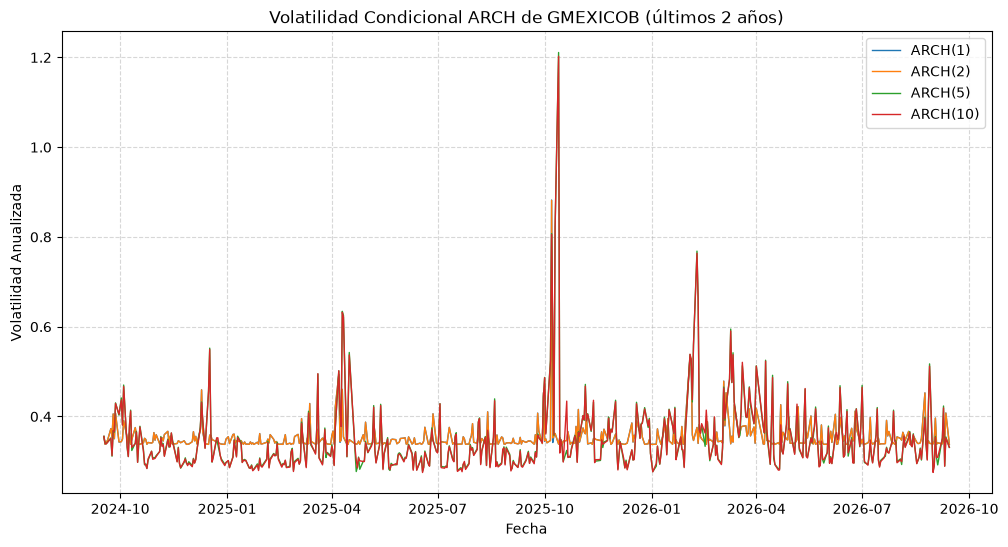

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))

for q in rezagos:
    vol_anual = np.sqrt(sigma2_arch[f'var_q{q}'] * 252)
    ax.plot(sigma2_arch.index, vol_anual, label=f'ARCH({q})', linewidth=1)

ax.set_xlabel('Fecha')
ax.set_ylabel('Volatilidad Anualizada')
ax.set_title('Volatilidad Condicional ARCH de GMEXICOB (últimos 2 años)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

save_path = os.path.join("..", "graficas", "arch_volatilidad.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()